In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib widget
%pwd

'/projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct'

In [2]:
import sys, os

print(os.getpid())

#os.environ['CUDA_LAUNCH_BLOCKING'] = '1' # force synchronization
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

def add_path(p: str):
    if p not in sys.path:
        sys.path.append(p)

add_path(os.environ['LP_ROOT'])
add_path(os.environ['PROJECT'])

import project

import torch
assert torch.cuda.is_available()

88629


# Gather examples

In [3]:
from pathlib import Path
data_root = Path(os.environ['PRIVATE']) / 'data' / 'BMC-4DCT'

manifest_path = data_root / 'metadata' / 'phase_manifest.csv'
manifest = project.fileio.load_csv(manifest_path)

case_data = manifest[manifest.case_valid].sort_values(by=['subject_num', 'study_num'])
case_list = case_data.case_id.unique().tolist()

len(case_list)

Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/metadata/phase_manifest.csv


47

In [4]:
config = project.fileio.load_config('2026-11-01_config.yaml')

config['dataset']['subjects'] = case_list
config['dataset']['state_pairs'] = [(50, 0)]
config['dataset']['pipeline_tags']['image_registration'] = 'gil'
config['dataset']['pipeline_tags']['material_properties'] = 'const'
config['dataset']['pipeline_tags']['field_interpolation'] = 'int'

project.utils.pprint(config['dataset'])

Loading 2026-11-01_config.yaml
dict(len=6)
├── 'name':          'BMC-4DCT'
├── 'root':          '/restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT'
├── 'subjects':      list(len=47)
|   ├── 0: '4DCT_1_1'
|   ├── 1: '4DCT_2_1'
|   ├── 2: '4DCT_2_2'
|   ├── 3: '4DCT_4_1'
|   ├── 4: '4DCT_6_1'
|   ├── 5: '4DCT_7_3'
|   ├── 6: '4DCT_8_1'
|   ├── 7: '4DCT_8_2'
|   ├── 8: '4DCT_10_1'
|   ├── 9: 'unknown_12_1'
|   └── <37 more items>
├── 'state_pairs':   list(len=1)
|   └── 0: tuple(len=2)
├── 'variant':       '2026-11-01'
└── 'pipeline_tags': dict(len=7)
    ├── 'image_resampling':    'iso'
    ├── 'image_segmentation':  'v3d'
    ├── 'image_registration':  'gil'
    ├── 'anatomical_regions':  'lung'
    ├── 'mesh_generation':     'rad'
    ├── 'field_interpolation': 'int'
    └── 'material_properties': 'const'


In [5]:
examples = project.api.get_examples(config['dataset'])

Gathering examples...
47 total


# Training run

In [6]:
#config['training']['model']['heads']['E']['v_max'] = 2e4
#config['training']['model']['heads']['E']['beta']  = 1.0
#config['training']['model']['heads']['E']['beta']  = 1.0
config['training']['pde_solver']['eps_err'] = 1e-12

project.utils.pprint(config['training'], max_depth=4, max_items=12)

dict(len=9)
├── 'task':               dict(len=3)
|   ├── 'inputs':  list(len=1)
|   |   └── 0: 'image'
|   ├── 'targets': list(len=1)
|   |   └── 0: 'E'
|   └── 'losses':  dict(len=1)
|       └── 'E': 'sim'
├── 'split':              dict(len=5)
|   ├── 'method':     'metadata'
|   ├── 'key':        'subject_num'
|   ├── 'test_ratio': 0.2
|   ├── 'val_ratio':  0.2
|   └── 'seed':       11
├── 'transform':          dict(len=8)
|   ├── 'normalize':      True
|   ├── 'image_mean':     -650.0
|   ├── 'image_std':      150.0
|   ├── 'apply_mask':     True
|   ├── 'do_augment':     False
|   ├── 'rand_rotate':    False
|   ├── 'rand_reflect':   False
|   └── 'rand_translate': 0.0
├── 'loaders':            dict(len=3)
|   ├── 'batch_size': 1
|   ├── 'shuffle':    True
|   └── 'seed':       1234
├── 'model':              dict(len=2)
|   ├── 'backbone': dict(len=11)
|   |   ├── 'type':          'UNet3D'
|   |   ├── 'out_channels':  8
|   |   ├── 'n_conv_units':  2
|   |   ├── 'n_unet_levels': 2

In [7]:
run_name = 'full_LE_eps'

Splitting data examples
All subject_num levels: 42 [1, 2, 4, 6, 7, 8, 10, 12, 13, 14, 15, 16, 17, 18, 19, 20, 22, 23, 26, 27, 28, 29, 30, 31, 32, 33, 34, 36, 37, 38, 39, 40, 42, 43, 44, 45, 47, 49, 50, 51, 52, 53]
Test ratio: 0.20
Val ratio:  0.20
Split seed: 11
Train subject_num levels: 26 [50, 2, 20, 10, 8, 45, 7, 49, 16, 34, 37, 1, 12, 32, 53, 14, 26, 4, 36, 13, 42, 6, 44, 38, 52, 23]
Test subject_num levels:  8 [17, 33, 43, 30, 31, 29, 47, 28]
Val subject_num levels:   8 [40, 18, 27, 39, 15, 51, 22, 19]
Train examples: 29 ['4DCT_10_1', '4DCT_1_1', '4DCT_2_1', '4DCT_2_2', '4DCT_4_1', '4DCT_6_1', '4DCT_7_3', '4DCT_8_1', '4DCT_8_2', 'unknown_12_1', 'unknown_13_1', 'unknown_14_1', 'unknown_16_1', 'unknown_20_1', 'unknown_23_1', 'unknown_26_1', 'unknown_32_1', 'unknown_34_1', 'unknown_36_1', 'unknown_37_1', 'unknown_38_1', 'unknown_42_1', 'unknown_42_4', 'unknown_44_1', 'unknown_45_1', 'unknown_49_1', 'unknown_50_1', 'unknown_52_1', 'unknown_53_1']
Test examples:  9 ['unknown_17_1', 'un

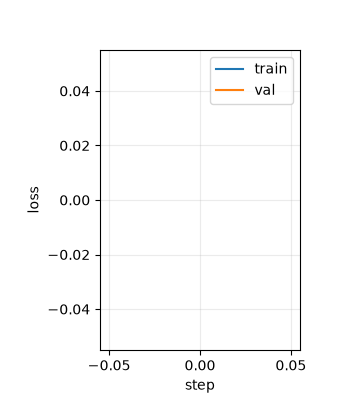

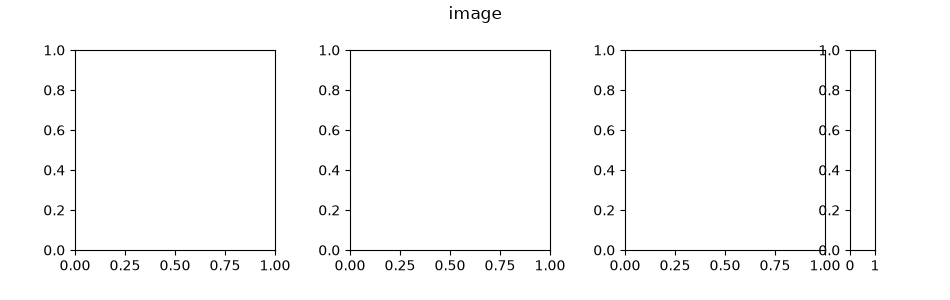

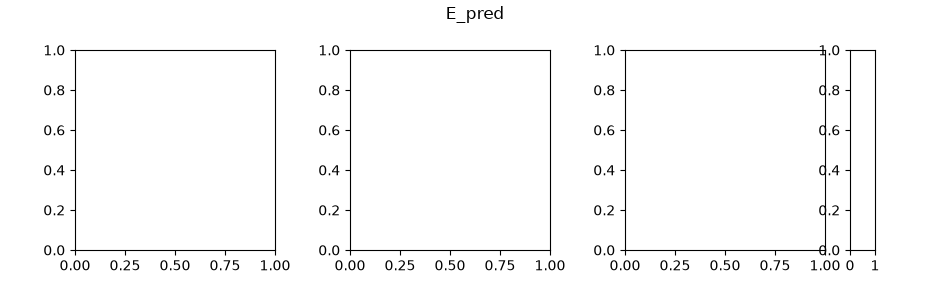

In [8]:
%autoreload
import project.training
trainer = project.training.get_trainer(examples, config['training'], run_name=run_name, use_callbacks=True)

In [10]:
%autoreload
# NOTES
# - very large: unknown_53_1 (700, 700, 347)
# - excess space: most of the images
# - clipped FOV: 4DCT_8_2, 4DCT_10_1

trainer.train(num_epochs=25, save_interval=1)

Training start
Saving outputs/training/full_LE_eps/checkpoint_0.pt
[Epoch 0 | test batch 1 | load data]  dt = 3.1s  curr_alloc = 13 GiB  curr_resvd = 13 GiB  mem_usage = 14/44 GiB  subject = unknown_17_1  img_size = (540, 540, 317)  n_verts = 32420
[Epoch 0 | test batch 1 | run batch]  dt = 2.4s  curr_alloc = 13 GiB  curr_resvd = 13 GiB  mem_usage = 15/44 GiB  loss = 0.1451  grad_norm = 0
[Epoch 0 | test batch 2 | load data]  dt = 4.1s  curr_alloc = 13 GiB  curr_resvd = 13 GiB  mem_usage = 15/44 GiB  subject = unknown_17_3  img_size = (567, 567, 327)  n_verts = 36424
[Epoch 0 | test batch 2 | run batch]  dt = 2.7s  curr_alloc = 13 GiB  curr_resvd = 14 GiB  mem_usage = 15/44 GiB  loss = 0.2633  grad_norm = 0
[Epoch 0 | test batch 3 | load data]  dt = 3.3s  curr_alloc = 13 GiB  curr_resvd = 14 GiB  mem_usage = 15/44 GiB  subject = unknown_28_1  img_size = (518, 518, 305)  n_verts = 41175
[Epoch 0 | test batch 3 | run batch]  dt = 2.4s  curr_alloc = 13 GiB  curr_resvd = 14 GiB  mem_usage 

OutOfMemoryError: CUDA out of memory. Tried to allocate 5.19 GiB. GPU 0 has a total capacity of 44.42 GiB of which 4.41 GiB is free. Including non-PyTorch memory, this process has 40.00 GiB memory in use. Of the allocated memory 38.32 GiB is allocated by PyTorch, and 271.57 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

# Evaluate outputs

In [13]:
run_name

'full_LE_beta'

In [11]:
import pandas as pd
df = pd.read_csv(f'outputs/training/{run_name}/eval_metrics.csv')
df

,epoch,phase,batch,loss,grad_norm,group,label,num_voxels,E_vox.mean,E_vox.std,...,u_cell.mean,u_cell.std,u_cell.rms,u_cell.mae,u_cell.mre,u_cell.rmse,u_cell.nrmse,res_cell.mean,res_cell.std,res_cell.rms
0,0,test,1,0.008647,0.0,NaN,NaN,2037548.0,1161.314234,300.282734,...,5.043641,3.666874,6.235726,1.587389,0.271266,2.199482,0.310852,0.000737,0.001581,0.001744
1,0,test,2,0.017543,0.0,NaN,NaN,2227797.0,1188.602083,299.880018,...,3.958193,2.938196,4.929532,2.039671,0.376060,2.977233,0.445404,0.000571,0.001414,0.001525
2,0,test,3,0.014993,0.0,NaN,NaN,2460214.0,1193.757437,302.656666,...,5.912784,3.663454,6.955710,2.013062,0.278689,2.684740,0.310600,0.000727,0.001648,0.001801
3,0,test,4,0.003210,0.0,NaN,NaN,3342098.0,1073.269136,340.705257,...,3.454245,1.561047,3.790604,0.781225,0.202674,1.001405,0.234059,0.000366,0.000826,0.000904
4,0,test,5,0.005082,0.0,NaN,NaN,2314763.0,1126.844946,335.073480,...,7.379753,3.568857,8.197408,1.209389,0.156044,1.597072,0.185683,0.000819,0.001602,0.001799
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
953,20,val,5,0.013022,0.0,NaN,NaN,3779263.0,3939.236467,3660.462730,...,6.347520,4.056151,7.532820,1.569728,0.231277,2.066662,0.246480,0.001400,0.003876,0.004122
954,20,val,6,0.002341,0.0,NaN,NaN,2045697.0,4125.328194,3991.971132,...,4.681384,2.097619,5.129850,0.831616,0.165544,1.064258,0.195982,0.001439,0.003508,0.003792
955,20,val,7,0.005549,0.0,NaN,NaN,2810119.0,3807.129884,3834.134642,...,9.842592,6.009572,11.532197,1.291102,0.125070,1.632502,0.134877,0.001717,0.004173,0.004513
956,20,val,8,0.019261,0.0,NaN,NaN,3088883.0,3917.376829,3924.059060,...,7.321073,4.900168,8.809640,2.138525,0.251477,2.818836,0.289487,0.002548,0.008098,0.008490


In [14]:
df.query('phase == "val"').groupby('epoch').loss.mean().sort_values().head(10)

epoch
11    0.006860
18    0.006908
17    0.006961
16    0.007037
13    0.007057
19    0.007068
20    0.007092
6     0.007109
14    0.007160
9     0.007161
Name: loss, dtype: float64

In [31]:
trainer.load_checkpoint(epoch=11)

Loading outputs/training/full_LE_beta/checkpoint_11.pt


In [32]:
outputs = trainer.run_batch(
    batch=next(iter(trainer.val_loader)), eval_mode=True
)

In [33]:
import numpy as np

affine = outputs['batch']['affine'][0].detach().cpu().numpy()
image  = outputs['batch']['image'][0,0].detach().cpu().numpy()
mask   = outputs['batch']['mask'][0,0].detach().cpu().numpy()
#E_true = outputs['batch']['E'][0,0].detach().cpu().numpy()
E_pred = outputs['preds']['E'][0,0].detach().cpu().numpy()
log_E_pred = np.log10(E_pred)

vox_spacing = tuple(float(v) for v in affine[:3,:3] @ np.ones(3))
vox_spacing

(-1.0, 1.0, 1.0)

In [34]:
import project.visual.matplotlib as mpl_viz
import matplotlib.pyplot as plt

img_kws = dict(cmap='gray', vmin=-1000, vmax=-500)
E_kws = dict(cmap='jet', vmin=0, vmax=1e4)
err_kws = dict(cmap='seismic', vmin=-1, vmax=1)

grid_kws = dict(cbar_width=0.2, padding=(0.5, 0.65, 0.35, 0.3))

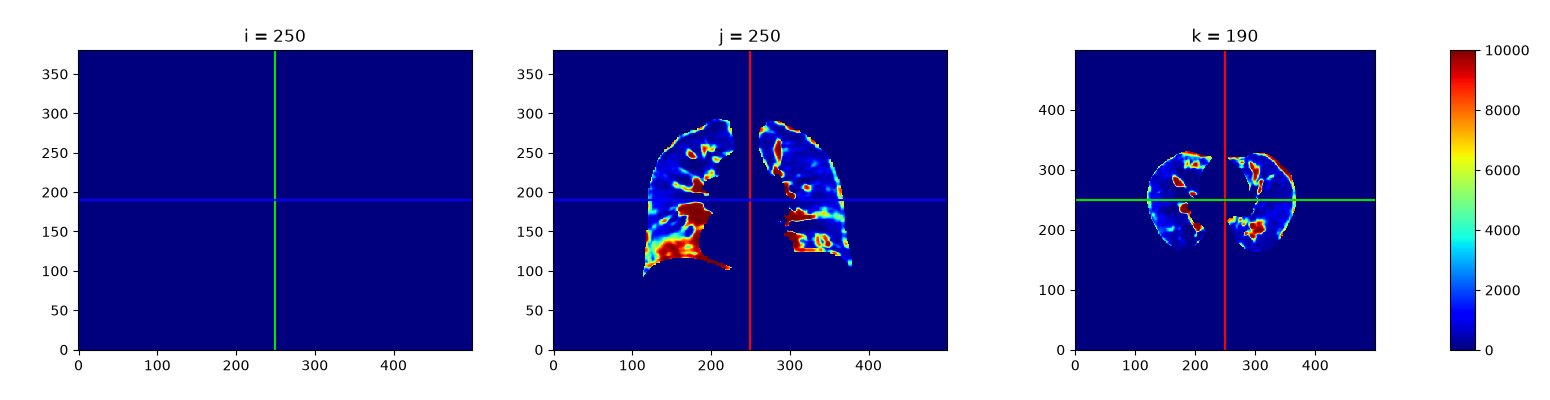

In [35]:
mpl_viz.SliceViewer(E_pred * mask, vox_spacing=vox_spacing, ax_width=4, ax_height=3, **E_kws)

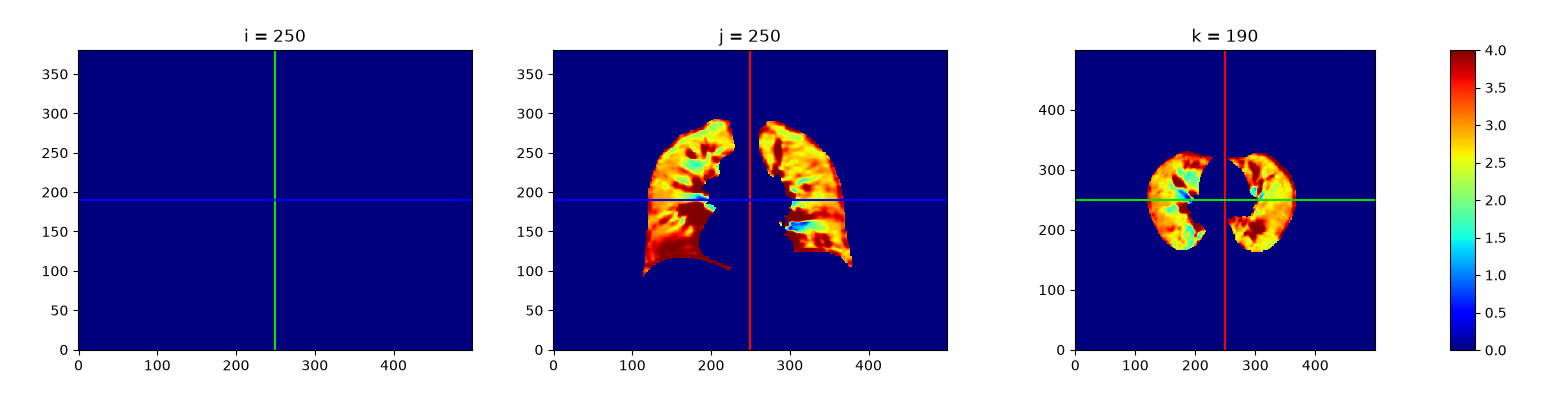

In [36]:
log_E_pred = np.log10(E_pred)

mpl_viz.SliceViewer(log_E_pred * mask, vox_spacing=vox_spacing, ax_width=4, ax_height=3, cmap='jet', clim=(0, 4))

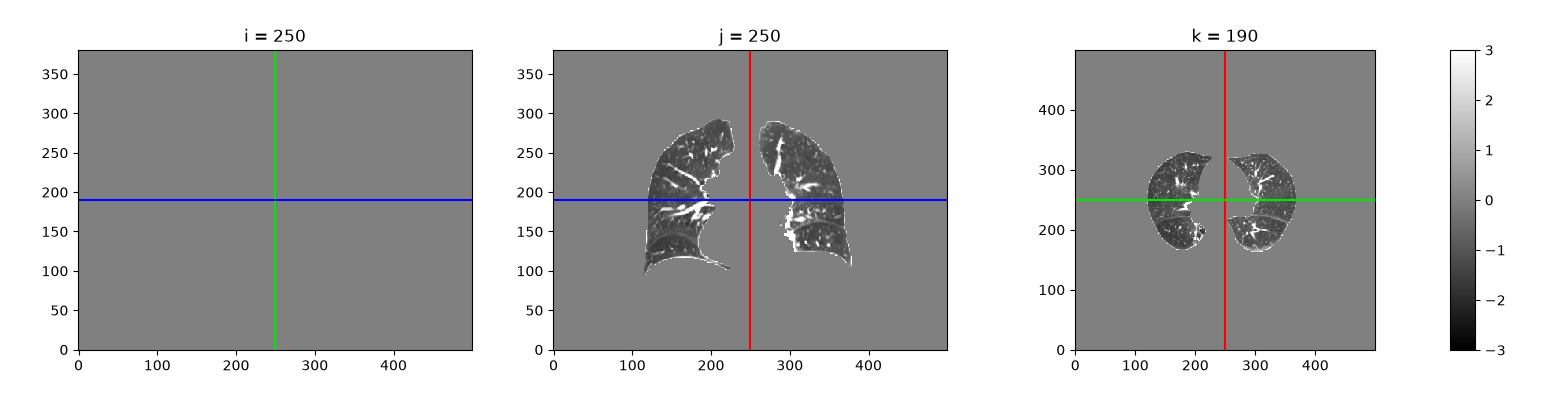

In [37]:
mpl_viz.SliceViewer(image * mask, vox_spacing=vox_spacing, ax_width=4, ax_height=3, cmap='gray', clim=(-3, 3))

In [38]:
def subplot_grid(
    n_rows, n_cols,
    ax_heights,
    ax_widths,
    spacing=(0.0,0.0), # hw
    padding=(0.0,0.0,0.0,0.0), # lrbt
    **subplot_kws
):
    h_spacing, w_spacing = tuple(spacing)
    l_pad, r_pad, b_pad, t_pad = tuple(padding)

    total_ax_height = sum(ax_heights)
    total_ax_width  = sum(ax_widths)

    total_h_spacing = (n_rows - 1) * h_spacing 
    total_w_spacing = (n_cols - 1) * w_spacing

    fig_height = total_ax_height + total_h_spacing + b_pad + t_pad
    fig_width  = total_ax_width  + total_w_spacing + l_pad + r_pad

    mean_ax_height = total_ax_height / n_rows
    mean_ax_width  = total_ax_width  / n_cols

    gridspec_kws = {
        'height_ratios': ax_heights,
        'width_ratios':  ax_widths,
        'hspace': h_spacing / mean_ax_height,
        'wspace': w_spacing / mean_ax_width,
        'left': l_pad / fig_width,
        'right': 1.0 - r_pad / fig_width,
        'bottom': b_pad / fig_height,
        'top': 1.0 - t_pad / fig_height
    }

    return plt.subplots(
        n_rows,
        n_cols,
        squeeze=False,
        figsize=(fig_width, fig_height),
        gridspec_kw=gridspec_kws,
        **subplot_kws
    )


In [39]:
import pandas as pd
opt_jobs = pd.read_parquet('2026-11-11_optimize/jobs.parquet').set_index(
    ['params.subject', 'params.curr_phase', 'params.material_type'],
    verify_integrity=True
)
opt_jobs

job_name  \
params.subject params.curr_phase params.material_type                         
unknown_15_1   40                LE                    job_8a2bd4710684b8ad   
                                 NH                    job_2da3d5020c366b7e   
               30                LE                    job_8d88d5a3cd7efc97   
                                 NH                    job_6b0c2f6c00bab50d   
               20                LE                    job_042057cc8cf46efa   
...                                                                     ...   
unknown_47_1   80                NH                    job_c6eaf2766feeed3c   
               70                LE                    job_2488c5739c7ceb06   
                                 NH                    job_10539679f82d7c50   
               60                LE                    job_7456dc260b74ec97   
                                 NH                    job_3916f33da912d4c1   

                                                       job_state  n_submits  \
params.subject params.curr_phase params.material_type                         
unknown_15_1   40                LE                    COMPLETED          1   
                                 NH                    COMPLETED          1   
               30                LE                    COMPLETED          1   
                                 NH                    COMPLETED          1   
               20                LE                    COMPLETED          1   
...                                                          ...        ...   
unknown_47_1   80                NH                    COMPLETED          1   
               70                LE                    COMPLETED          1   
                                 NH                    COMPLETED          1   
               60                LE                    COMPLETED          1   
                                 NH                    COMPLETED          1   

                                                        job_id  node_id  \
params.subject params.curr_phase params.material_type                     
unknown_15_1   40                LE                    8581752  scc-k02   
                                 NH                    8581753  scc-k02   
               30                LE                    8581754  scc-k02   
                                 NH                    8581755  scc-k01   
               20                LE                    8581756  scc-q34   
...                                                        ...      ...   
unknown_47_1   80                NH                    8582098  scc-214   
               70                LE                    8582099  scc-q30   
                                 NH                    8582100  scc-308   
               60                LE                    8582101  scc-307   
                                 NH                    8582102  scc-216   

                                                        runtime  \
params.subject params.curr_phase params.material_type             
unknown_15_1   40                LE                    00:10:05   
                                 NH                    00:30:41   
               30                LE                    00:08:44   
                                 NH                    00:36:31   
               20                LE                    00:05:08   
...                                                         ...   
unknown_47_1   80                NH                    00:33:45   
               70                LE                    00:06:35   
                                 NH                    00:15:28   
               60                LE                    00:05:07   
                                 NH                    00:21:04   

                                                                                                  stdout  \
params.subject params.curr_phase params.material_type  

In [40]:
ex = outputs['batch']['example'][0]
opt_job = opt_jobs.loc[ex.subject, 0, 'LE']
opt_job

job_name                                             job_288c4aa485fdd355
job_state                                                       COMPLETED
n_submits                                                               1
job_id                                                            8581760
node_id                                                           scc-q30
runtime                                                          00:06:16
stdout                  [step 33] loss = 5.2501e-04 (delta = 1.2628e-0...
stderr                                                                   
base_dir                /projectnb/batmanlab/mragoza/lung-project/note...
work_dir                /projectnb/batmanlab/mragoza/lung-project/note...
script_path             /projectnb/batmanlab/mragoza/lung-project/note...
output_path             /projectnb/batmanlab/mragoza/lung-project/note...
log_dir                 /projectnb/batmanlab/mragoza/lung-project/note...
stdout_path             /projectnb/bat

In [41]:
from pathlib import Path
E_base_path = Path(opt_job.work_dir) / 'outputs' / 'optimize' / 'default' / ex.subject / 'rasters' / 'E_pred.nii.gz'
E_base = project.fileio.load_nibabel(E_base_path).get_fdata() 

Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-11_optimize/job_288c4aa485fdd355/outputs/optimize/default/unknown_15_1/rasters/E_pred.nii.gz


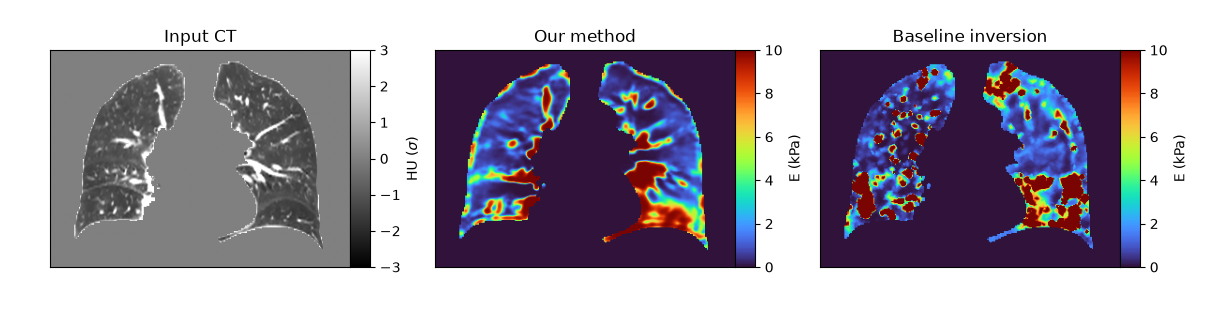

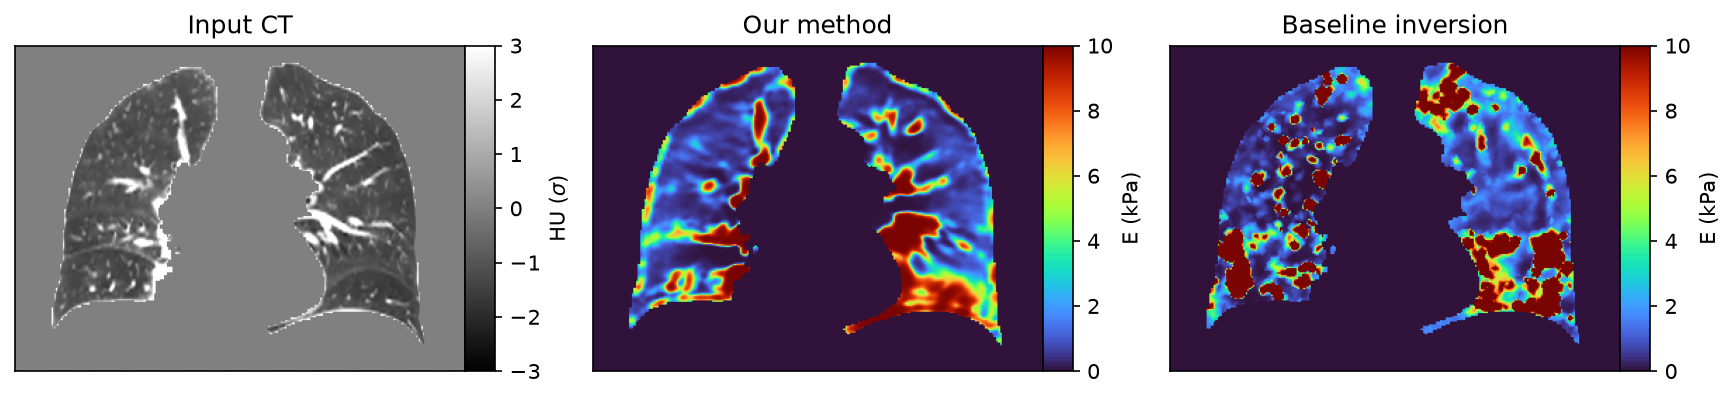

In [44]:
def _slice(array, crop=(95,85,75,75), idx=250):
    X, Y, Z = array.shape
    l, r, b, t = crop
    return array[l:X-r,idx,t:Z-b].T

fig, axes = subplot_grid(
    n_rows=1,
    n_cols=8,
    ax_heights=[2.17],
    ax_widths=[3,0.2,0.65,3,0.2,0.65,3,0.2],
    padding=[0.5,0.65,0.5,0.5]
)

im = axes[0,0].imshow(_slice(image), origin='lower', cmap='gray', clim=(-3,3))
axes[0,0].set_xticks([])
axes[0,0].set_yticks([])
axes[0,0].set_title('Input CT')

plt.colorbar(im, cax=axes[0,1], label='HU ($\sigma$)')

axes[0,2].set_axis_off()

im = axes[0,3].imshow(_slice(E_pred * mask / 1e3), origin='lower', cmap='turbo', clim=(0,10))
axes[0,3].set_xticks([])
axes[0,3].set_yticks([])
axes[0,3].set_title('Our method')

plt.colorbar(im, cax=axes[0,4], label='E (kPa)')

axes[0,5].set_axis_off()

im = axes[0,6].imshow(_slice(E_base / 1e3), origin='lower', cmap='turbo', clim=(0,10))
axes[0,6].set_xticks([])
axes[0,6].set_yticks([])
axes[0,6].set_title('Baseline inversion')

plt.colorbar(im, cax=axes[0,7], label='E (kPa)')

plt.pause(1.0)
fig